# World models: acting and imagining in one loop

An environment in Dew is two pure functions over a pytree: `reset(key)` starts an episode and
`step(state, action)` advances it, each answering a `TimeStep`. That is the shape of every JAX-native
simulator, and it is also the shape of a learned world model, whose state is a latent and whose step
is a network. So acting in a simulator and imagining in a world model are the same loop,
`env_rollout`: a `lax.scan` of a policy and a step.

This tutorial runs that loop three ways on MuJoCo Playground's `CartpoleBalance`: a random policy, a
PPO agent trained in the simulator, and a DreamerV3 agent that learns a world model from its replay and
trains its actor and critic inside it. Then comes Dreamer 4's world model at a small scale, trained by
shortcut forcing on video. It ends with a simulator outside JAX, a first-person drone race on HyperDrone,
and a privileged teacher learning to fly it.

## Setup

In [ ]:
%pip install -q "dewml[cuda13,playground,hyperdrone] @ git+https://github.com/AshishKumar4/dew@a233b3f34372e7d6caae2c4a446f1ea6d6ae7a36" --extra-index-url https://pypi.dewml.dev/simple

In [1]:
import time

import jax
import jax.numpy as jnp
import numpy as np
import optax

from dew import figures
from dew.rl.env import env_rollout, start
from dew.rl.playground import Playground, playground

TASK = "CartpoleBalance"
probe = Playground.load(TASK)
print(jax.devices()[0], "observation", probe.env.observation_size, "action", probe.action_size)

cuda:0 observation 5 action 1


## The loop

`playground(TASK, count)` is `count` copies of the task stepped together, each episode cut after
1000 steps as Playground trains them. A policy is `policy(params, observation, key, memory)`; a
random one ignores everything but its key.

In [2]:
env = playground(TASK, 256)

def random_policy(params, observation, key, memory):
    action = jax.random.uniform(key, (observation.shape[0], env.action_size), minval=-1, maxval=1)
    return action, {}, memory

rolled = jax.jit(lambda carry: env_rollout(env, random_policy, None, carry, 1000))
_, steps = rolled(start(env, jax.random.key(0)))
returns = np.asarray(steps.following.reward.sum(0))
print(f"random policy: mean return {returns.mean():.1f} over {len(returns)} episodes")

random policy: mean return 358.9 over 256 episodes


## PPO in the simulator

`ControlPPOObjective` is Brax's PPO: a tanh-squashed normal policy and a value network, the clipped
surrogate over advantages computed from the live critic. `ControlRollout` collects with the live policy
and serves each collection as several passes of minibatches, one an update.

In [3]:
import itertools

from dew.data.dataset import Loader
from dew.objectives.rl.control import ActorCritic, ControlPPOObjective, ControlRollout, episode_return
from dew.training import Trainer

objective = ControlPPOObjective(ActorCritic(probe.action_size), int(probe.env.observation_size),
                                discount=0.995, reward_scaling=10.0, entropy_cost=1e-2)
rollout = ControlRollout(objective, playground(TASK, 2048), unroll_length=30, unrolls=16, epochs=16,
                         minibatches=32)
idle = Loader(train=lambda partition: itertools.repeat({"step": np.zeros((1,), np.float32)}), val=None,
              records=1, batch=1)
began = time.perf_counter()
ppo = Trainer(objective, optax.adam(1e-3), key=jax.random.key(1), rollout=rollout).fit(idle, steps=8 * 512,
                                                                                        log_every=512)
print(f"{time.perf_counter() - began:.0f} s; greedy return",
      episode_return(objective, playground(TASK, 64), ppo.variables, jax.random.key(2), 1000))

╭─  dew · ActorCritic  ───────────────────────────────────────────────────────────────────────────────────────────╮
│ 268,387 parameters  ·  on 1 × NVIDIA RTX PRO 6000 Blackwell Server Edition  ·  batch 1  ·  float32              │
│                                                                                                                 │
│ ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  4096/4096  100%  314.2 step/s  0:00:41 │
│                                                                                                                 │
│ train                                                                                                           │
│   loss                      639.3  ▇▅▃▁█▆▅▇        ↑ 10%                                                        │
│   entropy                  0.5012  █▆▅▅▃▄▁▁        ↓ 20%                                                        │
│   pg_clipfrac             0.07669  ▅▄▆▂▁▁█▆        ↑ 22%                                                        │
│   policy                 -0.01535  ▆▇▁█▇█▁▃        ↓ 88%                                                        │
│   ppo_kl                  0.02181  ▄▂▆▁▂▂█▅        ↑ 29%                                                        │
│   value                     639.3  ▇▅▃▁█▆▅▇        ↑ 10%                                                        │
│   data_wait_ms            0.01125  ▁▂▂▃█▆▂▂       ↑ 1.6%                                                        │
│   grad_norm                 5,051  ▆▃▅▁█▆▆█        ↑ 74%                                                        │
│   pg_clipfrac_lower 0   compiles 1.000   cache_hits 31.00   cache_misses 732.0   peak_memory_gib 0.3770         │
│ throughput                                                                                                      │
│   step_time_ms              2.910  ▁█▂▂▂▂▁▁       ↓ 1.9%                                                        │
│   samples_per_sec         351,902  █▁▇▇▇▇██       ↑ 2.0%                                                        │
│   hlo_flops_util             4.5%  █▁▇▇▇▇██     ↑ 0.1 pt                                                        │
│   hfu                        4.5%  █▁▇▇▇▇██     ↑ 0.1 pt                                                        │
│   rollout_seconds           1.172  █▅▁▁▁▁▁▁        ↓ 17×                                                        │
│ optimizer                                                                                                       │
│   accepted 100.0%                                                                                               │
│ rollout                                                                                                         │
│   episode_return              nan  ▁▃█                                                                          │
╰──────────────────────────────────────────────────────────────────────────────────────────────────  ✓ finished  ─╯

╭─  ✓ ActorCritic  ───────────────────────────╮
│    trained  4096 steps in 0:00:42           │
│ first step  after 24.80 s                   │
│       then  236.0 step/s                    │
│    goodput  41.2% of the wall time in steps │
│ final loss  639.3                           │
╰─────────────────────────────────────────────╯

42 s; greedy return 988.1912841796875


## DreamerV3: a world model as an environment

`DreamerV3Objective` learns an RSSM from replayed windows: a block GRU's deterministic state and
categorical latents, decoders for the observation, reward and continuation. The world model is an
`Env` (`LatentEnv`): its state is the latent and its step the prior, so the actor and critic train on
`env_rollout` over it, from every replayed state.

In [4]:
from dew.objectives.rl.dreamer import DreamerRollout, DreamerV3Objective, WorldModel, episodes_return

sys_env = playground(TASK, 16)
dreamer = DreamerV3Objective(WorldModel(int(probe.env.observation_size), probe.action_size))
replay = DreamerRollout(dreamer, sys_env, capacity=4000, batch=16, length=64, train_ratio=1024.0, prefill=64)
began = time.perf_counter()
agent = Trainer(dreamer, optax.adam(1e-4), key=jax.random.key(3), rollout=replay).fit(idle, steps=20_000,
                                                                                       log_every=2000)
print(f"{time.perf_counter() - began:.0f} s, {replay.environment_steps} environment steps; return",
      episodes_return(dreamer, playground(TASK, 16), agent.variables, jax.random.key(4), 1000))

╭─  dew · WorldModel  ────────────────────────────────────────────────────────────────────────────────────────────╮
│ 637,446 parameters  ·  on 1 × NVIDIA RTX PRO 6000 Blackwell Server Edition  ·  batch 1  ·  float32              │
│                                                                                                                 │
│ ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  20000/20000  100%  60.4 step/s  0:06:18 │
│                                                                                                                 │
│ train                                                                                                           │
│   loss                        3.320  █▂▂▂▂▂▂▁▁▁        ↓ 65%                                                    │
│   imagined_return             166.3  ▁▅▆▆▆▇▇▇██       ↑ 785%                                                    │
│   loss_continue             0.02044  █▂▁▁▁▁▁▁▁▁       ↓ 1.2%                                                    │
│   loss_decoder              0.02624  █▄▆▆▆▄▅▂▁▅        ↓ 47%                                                    │
│   loss_dynamics               1.406  ▁▄▇▇▇▇█▆▆▇        ↑ 18%                                                    │
│   loss_policy             -0.004971  █▃▁▁▁▁▁▁▁▁       ↓ 101%                                                    │
│   loss_replay_value          0.9520  █▃▂▂▂▂▁▂▁▁        ↓ 85%                                                    │
│   loss_representation         1.406  ▁▄▇▇▇▇█▆▆▇        ↑ 18%                                                    │
│   loss_reward                0.5149  █▅▃▂▂▁▁▂▄▁        ↓ 30%                                                    │
│   loss_value                 0.9316  █▃▃▂▂▂▂▂▁▂        ↓ 80%                                                    │
│   return_scale                86.72  ▁▃▄▅▅▆▆▇██        ↑ 11×                                                    │
│   data_wait_ms              0.01279  ▅▄▁▇▆▄▆██▆       ↑ 1.2%                                                    │
│   grad_norm                   3.214  █▆▅▄▃▂▂▂▁▁        ↓ 70%                                                    │
│   compiles 1.000   cache_hits 171.0   cache_misses 1,182   peak_memory_gib 1.328                                │
│ throughput                                                                                                      │
│   step_time_ms                16.57  █▁▁▁▁▁▁▁▁▁        ↓ 12%                                                    │
│   samples_per_sec             965.6  ▁█████████        ↑ 14%                                                    │
│   hlo_flops_util               0.3%  ▁█████████            →                                                    │
│   hfu                          0.3%  ▁█████████            →                                                    │
│   rollout_seconds             25.37  █▁▁▁▁▁▁▁▁▁        ↓ 53%                                                    │
│ optimizer                                                                                                       │
│   accepted 100.0%                                                                                               │
│ rollout                                                                                                         │
│   episode_return                nan                                                                             │
╰──────────────────────────────────────────────────────────────────────────────────────────────────  ✓ finished  ─╯

╭─  ✓ WorldModel  ────────────────────────────╮
│    trained  20000 steps in 0:06:22          │
│ first step  after 46.50 s                   │
│       then  59.6 step/s                     │
│    goodput  87.8% of the wall time in steps │
│ final loss  3.320                           │
╰─────────────────────────────────────────────╯

382 s, 21024 environment steps; return 562.7863159179688


## Imagining

Start from replayed posterior states and let the world model run on under the agent's policy. The
imagined rewards are what the critic learns from; compare them with what the replay actually earned.

In [5]:
from dew.objectives.rl.dreamer import LatentEnv
from dew.rl.distributions import twohot_bins
from dew.rl.env import Carry

windows = replay.sample(jax.random.key(5))
model = dreamer.model.bind(agent.variables, rngs={"latent": jax.random.key(6)})
deter, stoch = model.initial((16,))
first = jnp.asarray(windows["first"]).at[:, 0].set(True)
previous = jnp.concatenate([jnp.zeros_like(windows["action"][:, :1]), windows["action"][:, :-1]], 1)
for t in range(32):
    deter, stoch, _ = dreamer.observe(model, deter, stoch, windows["observation"][:, t], previous[:, t], first[:, t])
world = LatentEnv(dreamer.model, agent.variables, twohot_bins())
state, feature = world.at(deter, stoch, jax.random.key(7))

def imagined_policy(params, feature, key, memory):
    mean, std = dreamer.model.apply(params, feature, method=WorldModel.policy)
    return jnp.clip(mean + std * jax.random.normal(key, mean.shape), -1, 1), {}, None

_, dream = env_rollout(world, imagined_policy, agent.variables, Carry(state, feature, jax.random.key(8)), 32,
                       reset=False)
figures.curve({"replayed": np.asarray(windows["reward"][:, 32:]).mean(0),
               "imagined": np.asarray(dream.following.reward).mean(1)}, x_label="step", y_label="reward")

Figure(460 x 290, 20 shapes)

## Dreamer 4's world model at a small scale

Dreamer 4 replaces the RSSM with a causal tokenizer and a transformer over its latents, trained by
shortcut forcing: each frame gets its own signal level and step size, and a large step learns to match
two of its own half steps, so four steps generate what diffusion forcing needs many for. Here it learns
bouncing-ball video and predicts eight frames from four.

╭─  dew · CausalTokenizer  ───────────────────────────────────────────────────────────────────────────────────────╮
│ 1.6M parameters  ·  on 1 × NVIDIA RTX PRO 6000 Blackwell Server Edition  ·  batch 32  ·  float32                │
│                                                                                                                 │
│ ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  2000/2000  100%  85.9 step/s  0:00:36 │
│                                                                                                                 │
│ train                                                                                                           │
│   loss                   0.1466  ▁█       ↑ 0.4%                                                                │
│   mse                    0.1466  ▁█       ↑ 0.4%                                                                │
│   data_wait_ms          0.01418  ▁█       ↑ 1.3%                                                                │
│   grad_norm              0.4106  █▁        ↓ 35%                                                                │
│   compiles                1.000  ▁▁            →                                                                │
│   cache_hits              202.0  ▁▁            →                                                                │
│   cache_misses            1,356  ▁▁            →                                                                │
│   peak_memory_gib         2.533  ▁█            →                                                                │
│ throughput                                                                                                      │
│   step_time_ms            11.67  █▁       ↓ 1.4%                                                                │
│   samples_per_sec         2,742  ▁█       ↑ 1.4%                                                                │
│   hlo_flops_util           5.4%  ▁█     ↑ 0.1 pt                                                                │
│   hfu                      5.4%  ▁█     ↑ 0.1 pt                                                                │
│ optimizer                                                                                                       │
│   accepted               100.0%  ▁▁            →                                                                │
╰──────────────────────────────────────────────────────────────────────────────────────────────────  ✓ finished  ─╯

╭─  ✓ CausalTokenizer  ───────────────────────╮
│    trained  2000 steps in 0:00:43           │
│ first step  after 19.44 s                   │
│       then  85.2 step/s                     │
│    goodput  54.7% of the wall time in steps │
│ final loss  0.1466                          │
╰─────────────────────────────────────────────╯

╭─  dew · Dynamics  ──────────────────────────────────────────────────────────────────────────────────────────────╮
│ 6.3M parameters  ·  on 1 × NVIDIA RTX PRO 6000 Blackwell Server Edition  ·  batch 32  ·  float32                │
│                                                                                                                 │
│ ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  3000/3000  100%  93.7 step/s  0:00:51 │
│                                                                                                                 │
│ train                                                                                                           │
│   loss                  0.01451  █▁▁        ↓ 69%                                                               │
│   frame_loss            0.01451  █▁▁        ↓ 69%                                                               │
│   data_wait_ms          0.01390  ▁█▄       ↑ 2.0%                                                               │
│   grad_norm              0.9453  █▂▁        ↓ 84%                                                               │
│   compiles 1.000   cache_hits 202.0   cache_misses 1,358   peak_memory_gib 2.533                                │
│ throughput                                                                                                      │
│   step_time_ms            10.67  █▁▁       ↓ 0.3%                                                               │
│   samples_per_sec         3,000  ▁██       ↑ 0.3%                                                               │
│   hlo_flops_util          10.0%  ▁██            →                                                               │
│   hfu                     10.0%  ▁██            →                                                               │
│ optimizer                                                                                                       │
│   accepted 100.0%                                                                                               │
╰──────────────────────────────────────────────────────────────────────────────────────────────────  ✓ finished  ─╯

╭─  ✓ Dynamics  ──────────────────────────────╮
│    trained  3000 steps in 0:00:58           │
│ first step  after 26.17 s                   │
│       then  93.7 step/s                     │
│    goodput  55.0% of the wall time in steps │
│ final loss  0.01451                         │
╰─────────────────────────────────────────────╯

Figure(527.2 x 120, 3 shapes)
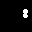
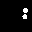
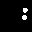
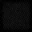
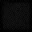
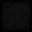
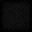
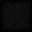
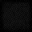
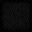
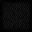

In [6]:
def bouncing(rows, frames, size, seed):
    """Videos [rows, frames, size, size, 1] in [-1, 1] of two balls bouncing off the walls."""
    rng = np.random.default_rng(seed)
    grid = np.stack(np.meshgrid(np.arange(size), np.arange(size), indexing="ij"), -1) + 0.5
    videos = np.full((rows, frames, size, size, 1), -1.0, np.float32)
    for video in videos:
        position, velocity = rng.uniform(3, size - 3, (2, 2)), rng.uniform(-1.5, 1.5, (2, 2))
        for frame in video:
            for ball in range(2):
                frame[np.sum(np.square(grid - position[ball]), -1) <= 2.5 ** 2, 0] = 1.0
            position = position + velocity
            velocity = np.where((position < 2.5) | (position > size - 2.5), -velocity, velocity)
            position = np.clip(position, 2.5, size - 2.5)
    return videos


from dew.objectives.world_model import CausalTokenizer, Dynamics, TokenizerObjective, WorldModelObjective

videos, held = bouncing(2048, 12, 32, 0), bouncing(8, 12, 32, 1)
clips = Loader(train=lambda partition: ({"video": videos[i:i + 32]} for i in itertools.cycle(range(0, 2048, 32))),
               val=None, records=2048, batch=32)
tokenizer = CausalTokenizer((32, 32, 1), width=128, depth=3, latents=16, bottleneck=8)
tokens = Trainer(TokenizerObjective(tokenizer), optax.adam(3e-4), key=jax.random.key(9)).fit(clips, steps=2000,
                                                                                            log_every=1000)
dynamics = Dynamics(latents=16, bottleneck=8, spatial=16, width=256, depth=6, frames=12)
world_model = WorldModelObjective(dynamics, tokenizer, tokens.variables)
trained = Trainer(world_model, optax.adam(3e-4), key=jax.random.key(10)).fit(clips, steps=3000, log_every=1000)
latents = world_model.latents(jnp.asarray(held))
predicted = world_model.generate(trained.variables, latents[:, :4], 8, jax.random.key(11), steps=4)
frames = np.asarray(tokenizer.apply(tokens.variables, predicted, method=CausalTokenizer.decode))
def pixels(video):
    return np.repeat(np.round((np.clip(video, -1, 1) + 1) * 127.5).astype(np.uint8), 3, -1)

figures.images([np.concatenate([pixels(held[0, 4:]), pixels(frames[0])])], columns=8, size=52,
               rows=["truth", "imagined"])

## A simulator outside JAX: first-person gate racing

A GPU simulator written in another framework cannot step inside a jitted program, so it is a
`Simulator`: stepped from the host a batch at a time, its arrays crossing by DLPack without a copy.
`dew.rl.flight` is a first-person drone race over any flight simulator. Each drone flies its own course
of gates, passing a gate only through its opening, and is randomized as a real quadrotor would be
(thrust, rate limits, latency, camera tilt). `dew.rl.hyperdrone` flies it on HyperDrone's quadrotor
dynamics and ray tracer. The policy sees the camera alone. The drone's state and the next gates' corners
are privileged: a teacher reads them, and a world model learns to predict them.

hyperdrone: preparing dynamics (CUDA); downloading build dependencies if needed...


hyperdrone: compiling dynamics configuration (CUDA)...


hyperdrone: compiling dynamics core (CUDA)...


hyperdrone: compiling dynamics configuration (CUDA)...


hyperlux: preparing renderer (OPTIX); downloading build dependencies if needed...


hyperlux: compiling renderer core (OPTIX)...


hyperlux: compiling renderer configuration (OPTIX)...


Figure(548 x 170, 4 shapes)
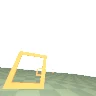
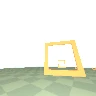
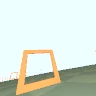
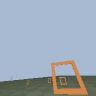
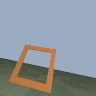
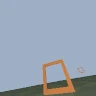
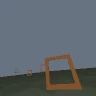
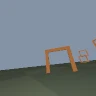
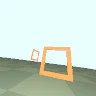
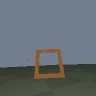
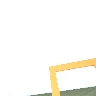
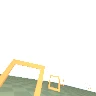
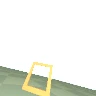
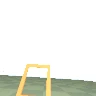
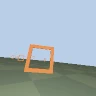
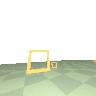
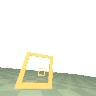
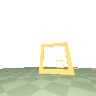
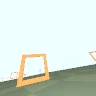
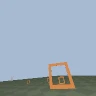
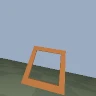
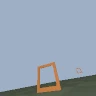
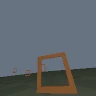
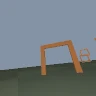
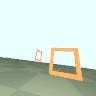
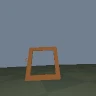
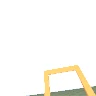
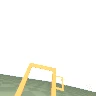
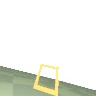
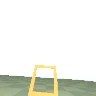
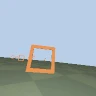
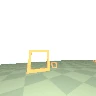

In [7]:
from dew.rl.flight import GATES, GateRace, Racing
from dew.rl.hyperdrone import HyperDroneFlight

racing = Racing()
drones = HyperDroneFlight(16, GATES, rate_limit=racing.rate_limit, headroom=1 + racing.spread)
race = GateRace(drones, racing, views=("image", "passed"))
shown = [np.asarray(race.reset(0)["image"])]
for _ in range(60):
    stepped = race.step(jnp.zeros((16, 4)))
shown.append(np.asarray(stepped.observation["image"]))
figures.images(shown, columns=8, size=64, captions=["start", "after a second of hovering"])

A privileged PPO teacher learns the race from the drone's state and the next gates' corners. It flies
4096 drones at a time, without images, and its greedy flight passes gates within minutes; here it is
scored before and after training on drones of a race of their own. `tools/fpv_race.py` runs the teacher
at length, then pretrains DreamerV3 on its demonstrations from the camera alone and trains it online.

In [8]:
from dew.rl.simulator import simulator_rollout, simulator_start

teacher_race = GateRace(HyperDroneFlight(4096, GATES, rate_limit=racing.rate_limit, headroom=1 + racing.spread),
                        racing, views=("teacher",))
teacher = ControlPPOObjective(ActorCritic(4, (256, 256, 256), (256, 256, 256, 256), spread=0.2), 43,
                              discount=0.99, clip=0.2, entropy_cost=1e-4, reads=("teacher",))
flights = ControlRollout(teacher, teacher_race, unroll_length=64, epochs=4, minibatches=32)
began = time.perf_counter()
taught = Trainer(teacher, optax.adam(3e-4), key=jax.random.key(12), rollout=flights).fit(idle, steps=12_800,
                                                                                          log_every=1280)
print(f"{time.perf_counter() - began:.0f} s of training")

judge = GateRace(HyperDroneFlight(256, GATES, rate_limit=racing.rate_limit, headroom=1 + racing.spread),
                 racing, views=("teacher", "passed"))
for name, params in (("fresh", teacher.init(jax.random.key(13))), ("trained", taught.variables)):
    _, flown = simulator_rollout(judge, teacher.greedy, params, simulator_start(judge, jax.random.key(14)),
                                 racing.max_steps)
    passed = np.asarray(flown.following.observation["passed"]).max(0)
    crashes = np.asarray(flown.following.terminated).sum(0)
    print(f"{name} teacher over {racing.episode_seconds:.0f} s: {passed.mean():.1f} gates in its best episode, "
          f"{crashes.mean():.1f} crashes a drone")

hyperdrone: compiling dynamics configuration (CUDA)...


╭─  dew · ActorCritic  ───────────────────────────────────────────────────────────────────────────────────────────╮
│ 353,801 parameters  ·  on 1 × NVIDIA RTX PRO 6000 Blackwell Server Edition  ·  batch 1  ·  float32              │
│                                                                                                                 │
│ ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  12800/12800  100%  207.7 step/s  0:01:13 │
│                                                                                                                 │
│ train                                                                                                           │
│   loss                     0.2470  ▅▃▂▁▃▂▄█▄▂        ↓ 49%                                                      │
│   entropy                  -5.041  █▇▆▅▄▃▃▂▂▁        ↓ 95%                                                      │
│   pg_clipfrac             0.09644  ▆▆▅█▁▄▄▅█▆       ↑ 5.6%                                                      │
│   policy                7.368e-04  ▁▃▆▇▃▅▅▄█▆       ↑ 123%                                                      │
│   ppo_kl                 0.009836  █▆▃▇▁▄▆▄█▅        ↓ 43%                                                      │
│   value                    0.2458  ▆▃▂▁▄▃▄█▄▂        ↓ 50%                                                      │
│   data_wait_ms            0.01149  ▅▁▁▂█▁▁▁▁▂       ↓ 7.5%                                                      │
│   grad_norm                 4.152  ▄▂▁▃▄▆▇██▇        ↑ 65%                                                      │
│   pg_clipfrac_lower 0   compiles 1.000   cache_hits 202.0   cache_misses 2,289   peak_memory_gib 2.533          │
│ throughput                                                                                                      │
│   step_time_ms              4.955  ▂▃▂▂█▁▁▁▂▂       ↓ 0.2%                                                      │
│   samples_per_sec          25,833  ▇▆▇▇▁███▇▇       ↑ 0.2%                                                      │
│   hlo_flops_util             0.8%  ▇▆▇▇▁███▇▇            →                                                      │
│   hfu                        0.8%  ▇▆▇▇▁███▇▇            →                                                      │
│   rollout_seconds           4.948  █▁▁▁▂▁▁▁▁▁        ↓ 52%                                                      │
│ optimizer                                                                                                       │
│   accepted 100.0%                                                                                               │
│ rollout                                                                                                         │
│   episode_return            69.45  ▁▁▁▂▂▂▃▄▆█       ↑ 605%                                                      │
╰──────────────────────────────────────────────────────────────────────────────────────────────────  ✓ finished  ─╯

╭─  ✓ ActorCritic  ───────────────────────────╮
│    trained  12800 steps in 0:01:14          │
│ first step  after 9.73 s                    │
│       then  199.7 step/s                    │
│    goodput  86.8% of the wall time in steps │
│ final loss  0.2470                          │
╰─────────────────────────────────────────────╯

74 s of training


hyperdrone: compiling dynamics configuration (CUDA)...


fresh teacher over 25 s: 0.0 gates in its best episode, 17.5 crashes a drone


trained teacher over 25 s: 1.4 gates in its best episode, 13.1 crashes a drone
